# Mixed-phase clouds (+ ERA5 data)

An idealised mixed-phase cloud, defined by a liquid and an ice profile file, over open ocean and over sea ice. Mixed-phase clouds contain both liquid water and ice crystals and are common in the Arctic. The atmosphere is an ERA5 reanalysis profile streamed from Google Cloud Storage, which needs `gcsfs` and network access.

In [1]:
import pyradtran  # Registers the .pyradtran xarray accessor
from pyradtran import Var
from pyradtran import load_config
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from pathlib import Path
import pandas as pd
import logging

logging.getLogger('pyradtran').setLevel(logging.WARNING)  # warnings only

# ── Solar config ─────────────────────────────────────────────────────────────
cfg_solar = load_config()
cfg_solar.simulation_defaults.rte_solver           = "disort"
cfg_solar.simulation_defaults.mol_abs_param        = "reptran per_nm"
cfg_solar.simulation_defaults.source               = "solar"
cfg_solar.simulation_defaults.wavelength_nm        = [400, 3200]
cfg_solar.simulation_defaults.integrate_wavelength = True
cfg_solar.simulation_defaults.output_columns       = ["edir", "edn", "eup", "enet"]
cfg_solar.paths.atmosphere_profile                 = "afglsw"   # sub-arctic winter background above ERA5
cfg_solar.execution.max_workers                    = 8
cfg_solar.execution.cleanup_temp_files             = False
solar_config_path = Path("config/cloud_solar.yaml")
cfg_solar.to_yaml(solar_config_path)

# ── Thermal config ────────────────────────────────────────────────────────────
cfg_thermal = load_config()
cfg_thermal.simulation_defaults.rte_solver           = "disort"
cfg_thermal.simulation_defaults.mol_abs_param        = "reptran medium"
cfg_thermal.simulation_defaults.source               = "thermal"
cfg_thermal.simulation_defaults.wavelength_nm        = [4500, 42000]
cfg_thermal.simulation_defaults.integrate_wavelength = True
cfg_thermal.simulation_defaults.output_columns       = ["edn", "eup", "enet"]
cfg_thermal.paths.atmosphere_profile                 = "afglsw"
cfg_thermal.execution.max_workers                    = 8
cfg_thermal.execution.cleanup_temp_files             = False
thermal_config_path = Path("config/cloud_thermal.yaml")
cfg_thermal.to_yaml(thermal_config_path)

print(f"Solar config:   {solar_config_path}")
print(f"Thermal config: {thermal_config_path}")

Solar config:   config/cloud_solar.yaml
Thermal config: config/cloud_thermal.yaml


## Cloud files

libRadtran takes a mixed-phase cloud as two separate files: one for liquid water (`wc_file`) and one for ice crystals (`ic_file`). Each lists altitude, content (LWC or IWC in g m⁻³) and effective radius (µm), top first. The value on a row applies to the layer between that level and the row above; the top row only closes the cloud ({doc}`/guide/clouds`).

Liquid water (`work/mixed_phase.wc`), LWC increasing towards cloud top:
```text
#      z     LWC    R_eff
#     (km)  (g/m³)  (µm)
      4.0    0.00   12.0     <- cloud top, value unused
      3.5    0.05   12.0     <- layer 3.5-4.0 km
      3.0    0.04   11.0
      2.5    0.03   10.0
      2.0    0.02    8.0     <- layer 2.0-2.5 km, cloud base
```

Ice crystals (`work/mixed_phase.ic`), constant IWC:
```text
#      z     IWC    R_eff
#     (km)  (g/m³)  (µm)
      4.0    0.00   20.0
      2.0    0.02   20.0     <- layer 2.0-4.0 km
```

The liquid water path is 0.5 km × (0.02 + 0.03 + 0.04 + 0.05) g m⁻³ = 70 g m⁻², a visible optical thickness of about 10; the ice water path is 40 g m⁻² ($\tau \approx 3$ with 20 µm crystals).

In [2]:
wc_content = """\
#      z     LWC    R_eff
#     (km)  (g/m^3) (um)
      4.0    0.00   12.0
      3.5    0.05   12.0
      3.0    0.04   11.0
      2.5    0.03   10.0
      2.0    0.02    8.0
"""

ic_content = """\
#      z     IWC    R_eff
#     (km)  (g/m^3) (um)
      4.0    0.00   20.0
      2.0    0.02   20.0
"""

wc_file_path = Path('work/mixed_phase.wc')
ic_file_path = Path('work/mixed_phase.ic')
wc_file_path.parent.mkdir(parents=True, exist_ok=True)
wc_file_path.write_text(wc_content)
ic_file_path.write_text(ic_content)
print(f"Cloud files written to {wc_file_path} and {ic_file_path}")

Cloud files written to work/mixed_phase.wc and work/mixed_phase.ic


## Arctic scenario

80° N, 0° E on 3 April 2020 at 12 UTC, over two contrasting surfaces on a `surface` dimension:

1. Open ocean: albedo 0.06, surface temperature −1.8 °C (sea water at its freezing point)
2. Sea ice: albedo 0.8, surface temperature −15 °C

In the thermal run the albedo sets the emissivity, $\varepsilon = 1 - \alpha$. A thermal emissivity of 0.2 for snow-covered sea ice would be far too low, so the thermal run uses albedo 0.02 ($\varepsilon = 0.98$) for both surfaces. The cloud is the same in both, so the difference in its radiative effect comes from the surface.

In [3]:
ds = xr.Dataset(
    coords={
        'time'      : [pd.Timestamp('2020-04-03T12:00:00')],
        'latitude'  : ('time', [80.0]),
        'longitude' : ('time', [0.0]),
        'surface'   : ['ocean', 'sea ice'],
        'altitude'  : ('altitude', np.arange(0, 10, 0.5)),   # output levels, km
    },
    data_vars={
        'surface_temperature' : ('surface', [271.35, 258.15]),  # K: -1.8 °C and -15 °C
        'solar_albedo'        : ('surface', [0.06, 0.8]),
    }
)

ds

<xarray.Dataset> Size: 272B
Dimensions:              (surface: 2, time: 1, altitude: 20)
Coordinates:
  * time                 (time) datetime64[ns] 8B 2020-04-03T12:00:00
    latitude             (time) float64 8B 80.0
    longitude            (time) float64 8B 0.0
  * surface              (surface) <U7 56B 'ocean' 'sea ice'
  * altitude             (altitude) float64 160B 0.0 0.5 1.0 1.5 ... 8.5 9.0 9.5
Data variables:
    surface_temperature  (surface) float64 16B 271.4 258.1
    solar_albedo         (surface) float64 16B 0.06 0.8

## ERA5 atmospheric profile

Temperature, humidity and geopotential come from the ERA5 grid point nearest to 80° N, 0° E at the time of the scenario, 3 April 2020, 12 UTC. A coarse (2.8°) ARCO-ERA5 copy is enough here. `era5_atmosphere=` accepts the raw ARCO names; {doc}`era5_atmosphere` explains the ERA5 input.

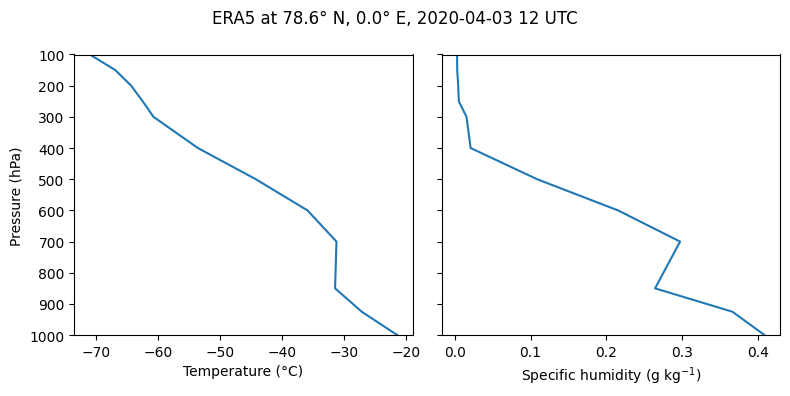

In [4]:
import os
import warnings
os.environ.setdefault('GRPC_VERBOSITY', 'ERROR')   # silence gRPC fork notices from gcsfs
warnings.filterwarnings('ignore', category=FutureWarning, module='google')
warnings.filterwarnings('ignore', message='IProgress not found')
import gcsfs

gcs = gcsfs.GCSFileSystem(token='anon')
path = 'gs://gcp-public-data-arco-era5/ar/1959-2022-6h-128x64_equiangular_with_poles_conservative.zarr/'
full_era5 = xr.open_zarr(gcs.get_mapper(path), chunks=None)

# One column at the scenario time, loaded into memory
era5 = full_era5[['temperature', 'specific_humidity', 'geopotential']].sel(
    time='2020-04-03T12:00:00', latitude=80.0, longitude=0.0, method='nearest',
).load()

fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
(era5['temperature'] - 273.15).plot(y='level', ax=ax[0])
(era5['specific_humidity'] * 1e3).plot(y='level', ax=ax[1])
ax[0].set_xlabel('Temperature (°C)')
ax[1].set_xlabel('Specific humidity (g kg$^{-1}$)')
ax[0].set_ylabel('Pressure (hPa)')
ax[1].set_ylabel('')
for a in ax:
    a.set_title('')
ax[0].set_ylim(1000, 100)
fig.suptitle(f"ERA5 at {float(era5.latitude):.1f}° N, {float(era5.longitude):.1f}° E, "
             f"{pd.Timestamp(era5.time.values):%Y-%m-%d %H} UTC")
plt.tight_layout()
plt.show()

## Solar and thermal runs

Both runs use the two cloud files. In the solar run `'wc_modify': ['tau550 set 10']` pins the liquid-cloud optical thickness at 550 nm to 10 and scales the other wavelengths accordingly. The option needs 550 nm inside the simulated band, so the thermal run (4.5–42 µm) uses the file as it is, whose optical thickness is about 10 already.

In [5]:
clouds = {
    'wc_file 1D': str(wc_file_path),
    'ic_file 1D': str(ic_file_path),
}

ds_sim_solar = ds.pyradtran.run(
    config_path=solar_config_path,
    era5_atmosphere=era5,
    params={
        **clouds,
        'albedo': Var('solar_albedo'),
        'wc_modify': ['tau550 set 10'],
    },
    show_progress=False,
)

ds_sim_thermal = ds.pyradtran.run(
    config_path=thermal_config_path,
    era5_atmosphere=era5,
    params={
        **clouds,
        'sur_temperature': Var('surface_temperature'),
        'albedo': 0.02,          # emissivity 0.98
    },
    show_progress=False,
)

## Net irradiance profiles

Net thermal, solar and total irradiance against altitude for each surface (solar output converted from mW m⁻² to W m⁻²). The grey band marks the cloud layer (2–4 km).

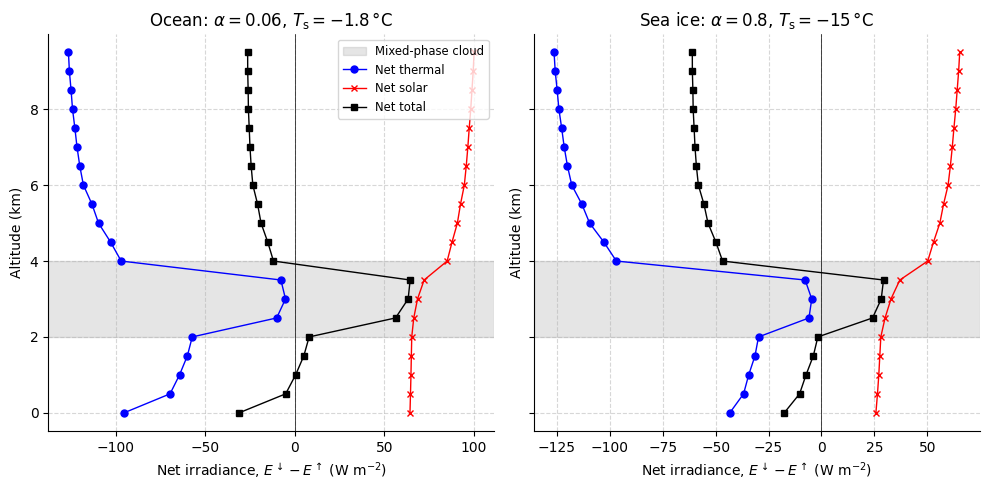

                  net solar  net thermal  net total
surface altitude                                   
ocean   0.0            64.2        -95.3      -31.1
        2.0            65.2        -57.3        8.0
        2.5            66.3        -10.2       56.2
        3.5            72.1         -7.8       64.3
        4.0            85.0        -96.9      -12.0
        9.5           100.0       -126.3      -26.4
sea ice 0.0            25.7        -43.3      -17.6
        2.0            28.0        -29.7       -1.7
        2.5            30.0         -5.9       24.1
        3.5            37.0         -7.7       29.3
        4.0            50.2        -96.9      -46.7
        9.5            65.3       -126.3      -61.0


In [6]:
net_solar = ds_sim_solar.enet.squeeze('time') / 1e3     # W m-2
net_thermal = ds_sim_thermal.enet.squeeze('time')       # W m-2
net = net_solar + net_thermal

titles = {
    'ocean': r'Ocean: $\alpha=0.06$, $T_\mathrm{s}=-1.8\,$°C',
    'sea ice': r'Sea ice: $\alpha=0.8$, $T_\mathrm{s}=-15\,$°C',
}
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for ax, surf in zip(axes, ds.surface.values):
    ax.axhspan(2.0, 4.0, color='gray', alpha=0.2, label='Mixed-phase cloud')
    net_thermal.sel(surface=surf).plot(y='altitude', ax=ax, marker='o', color='blue', label='Net thermal', lw=1, markersize=5)
    net_solar.sel(surface=surf).plot(y='altitude', ax=ax, marker='x', color='red', label='Net solar', lw=1, markersize=5)
    net.sel(surface=surf).plot(y='altitude', ax=ax, marker='s', color='black', label='Net total', lw=1, markersize=5)
    ax.axvline(0, color='k', lw=0.5)
    ax.set_xlabel(r'Net irradiance, $E^\downarrow - E^\uparrow$ (W m$^{-2}$)')
    ax.set_ylabel('Altitude (km)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_title(titles[surf])
axes[0].legend(fontsize='small')
plt.tight_layout()
plt.show()

print(xr.Dataset({'net solar': net_solar, 'net thermal': net_thermal, 'net total': net})
      .drop_vars('time').sel(altitude=[0.0, 2.0, 2.5, 3.5, 4.0, 9.5]).to_dataframe().round(1))

The flux difference across a layer is the energy it absorbs:

- **Cloud top** (3.5–4.0 km): thermal emission to space dominates. The layer loses about 76 W m⁻² in total over both surfaces; the solar absorption in the cloud (about 20 W m⁻²) offsets only a small part of the longwave loss.
- **Cloud base** (2.0–2.5 km): the layer absorbs thermal emission from below and warms, by about 48 W m⁻² over the ocean and 26 W m⁻² over the colder sea ice.
- **Surface**: the dark ocean absorbs 64 W m⁻² of sunlight, sea ice only 26 W m⁻². The warmer ocean also emits more, so its net thermal loss (−95 W m⁻²) is about twice that of sea ice (−43 W m⁻²). The total surface budget is negative in both cases, −31 W m⁻² over the ocean and −18 W m⁻² over sea ice.
- **Above the cloud** the net thermal irradiance is the same for both surfaces: the cloud hides the surface from space. The net solar irradiance at 9.5 km is lower over sea ice because more sunlight is reflected through the cloud.

A clear-sky run of the same scene (drop the two cloud files) gives the cloud radiative effect; see {doc}`/guide/clouds`.